# Historical dataset sanity

Reads one published `historical-payments` dataset version and reports volume, scenario mix, skew, cardinality, the schema cutover, duplicate exports and physical layout. Set `DATASET` to `s3://synthetic-source/historical/<version>` (with `AWS_ACCESS_KEY_ID`/`AWS_SECRET_ACCESS_KEY`) or a local directory.

In [1]:
import json
import os

import duckdb
import matplotlib.pyplot as plt

DATASET = os.environ.get("DATASET", "s3://synthetic-source/historical/v4").rstrip("/")
db = duckdb.connect()
db.execute("SET TimeZone = 'UTC'")
if DATASET.startswith("s3://"):
    db.execute(
        "CREATE SECRET (TYPE s3, KEY_ID ?, SECRET ?, ENDPOINT 'minio.home.phuchoang.sbs', URL_STYLE 'path', REGION 'us-east-1')",
        [os.environ["AWS_ACCESS_KEY_ID"], os.environ["AWS_SECRET_ACCESS_KEY"]],
    )
manifest = json.loads(db.sql(f"SELECT content FROM read_text('{DATASET}/manifest.json')").fetchone()[0])
events = f"read_parquet('{DATASET}/payment_events/*/*.parquet', union_by_name = true, hive_partitioning = false)"
labels = f"read_parquet('{DATASET}/fraud_labels/*/*.parquet', hive_partitioning = false)"
print(manifest["dataset_version"], manifest["validation"], "history end", manifest["history_end"])

v4 {'fraud-labels': 'passed', 'payment-events': 'passed'} history end 2026-09-29T00:58:44+00:00


## Volume and scenario mix

Fraud rate per scenario uses simulation truth per attempt; chargebacks are the delayed labels training will see.

In [2]:
db.sql(f"""
SELECT scenario, count(*) AS attempts, round(100 * count(*) / sum(count(*)) OVER (), 3) AS pct_attempts,
       count(*) FILTER (is_fraud) AS fraud_attempts
FROM {labels} WHERE source = 'LABEL_SOURCE_SIMULATION_TRUTH' GROUP BY ALL ORDER BY attempts DESC
""").show()
db.sql(f"""
SELECT count(*) AS event_rows, count(DISTINCT event_id) AS unique_events,
       round(1 - count(DISTINCT event_id) / count(*), 4) AS duplicate_rate,
       count(DISTINCT payment_id) AS payments,
       (SELECT count(*) FROM {labels} WHERE source = 'LABEL_SOURCE_CHARGEBACK') AS chargebacks
FROM {events}
""").show()
print("configured duplicate rate", manifest["configured"]["duplicate_rate"])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────────────────────┬──────────┬──────────────┬────────────────┐
│        scenario        │ attempts │ pct_attempts │ fraud_attempts │
│        varchar         │  int64   │    double    │     int64      │
├────────────────────────┼──────────┼──────────────┼────────────────┤
│ legitimate             │   412397 │       95.836 │              0 │
│ stolen_card_new_device │    11871 │        2.759 │          11871 │
│ account_takeover       │     3270 │         0.76 │           3270 │
│ card_testing           │     1225 │        0.285 │           1225 │
│ friendly_fraud         │     1105 │        0.257 │              0 │
│ obvious_high_value     │      447 │        0.104 │            447 │
└────────────────────────┴──────────┴──────────────┴────────────────┘



FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────────┬───────────────┬────────────────┬──────────┬─────────────┐
│ event_rows │ unique_events │ duplicate_rate │ payments │ chargebacks │
│   int64    │     int64     │     double     │  int64   │    int64    │
├────────────┼───────────────┼────────────────┼──────────┼─────────────┤
│    2215360 │       2171358 │         0.0199 │   420392 │       13252 │
└────────────┴───────────────┴────────────────┴──────────┴─────────────┘

configured duplicate rate 0.02


## Outcomes and decision policy

Approval, risk and processor declines per scenario under `sim-rules-v1`.

In [3]:
db.sql(f"""
WITH outcome AS (
  SELECT coalesce(attempt_declined.attempt_id, payment_succeeded.attempt_id) AS attempt_id,
         CASE WHEN payment_succeeded IS NOT NULL THEN 'succeeded' ELSE attempt_declined.source END AS result
  FROM (SELECT DISTINCT * FROM {events}) WHERE attempt_declined IS NOT NULL OR payment_succeeded IS NOT NULL
)
SELECT scenario, result, count(*) AS attempts
FROM {labels} l JOIN outcome USING (attempt_id)
WHERE source = 'LABEL_SOURCE_SIMULATION_TRUTH' GROUP BY ALL ORDER BY scenario, attempts DESC
""").show(max_rows=40)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────────────────────┬──────────────────────────┬──────────┐
│        scenario        │          result          │ attempts │
│        varchar         │         varchar          │  int64   │
├────────────────────────┼──────────────────────────┼──────────┤
│ account_takeover       │ succeeded                │     2156 │
│ account_takeover       │ DECLINE_SOURCE_RISK      │      967 │
│ account_takeover       │ DECLINE_SOURCE_PROCESSOR │      147 │
│ card_testing           │ DECLINE_SOURCE_PROCESSOR │      961 │
│ card_testing           │ succeeded                │      249 │
│ card_testing           │ DECLINE_SOURCE_RISK      │       15 │
│ friendly_fraud         │ succeeded                │     1105 │
│ legitimate             │ succeeded                │   382922 │
│ legitimate             │ DECLINE_SOURCE_PROCESSOR │    29237 │
│ legitimate             │ DECLINE_SOURCE_RISK      │      238 │
│ obvious_high_value     │ succeeded                │      414 │
│ obvious_high_value     

## Amounts, categories and merchant skew

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
electronics,138006.0,153.25,89.76,0.50,100.36,134.84,182.52,3166.72
fashion,37973.0,55.45,33.75,0.50,35.20,48.38,66.44,646.88
grocery,28377.0,30.01,22.40,0.50,17.34,24.70,35.85,674.56
home,67838.0,81.71,46.99,0.52,54.00,72.13,96.62,2028.16
travel,10792.0,286.34,169.45,54.42,192.66,252.38,333.46,3882.16


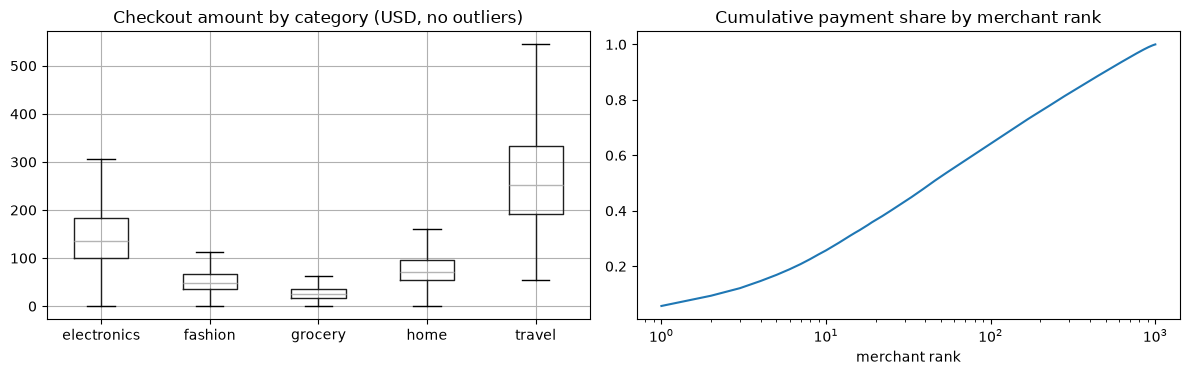

In [4]:
created = db.sql(f"""
SELECT payment_created.snapshot.merchant_category AS category,
       payment_created.snapshot.total.minor_units / 100.0 AS amount,
       payment_created.merchant.merchant_id AS merchant
FROM {events} WHERE payment_created IS NOT NULL
""").df().drop_duplicates()
shares = created.groupby("merchant").size().sort_values(ascending=False).cumsum() / len(created)
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
created.boxplot(column="amount", by="category", ax=left, showfliers=False)
left.set_title("Checkout amount by category (USD, no outliers)")
left.set_xlabel("")
right.plot(range(1, len(shares) + 1), shares.values)
right.set_xscale("log")
right.set_title("Cumulative payment share by merchant rank")
right.set_xlabel("merchant rank")
fig.suptitle("")
plt.tight_layout()
created.groupby("category").amount.describe().round(2)

## Cardinality

Approximate distinct counts of the high-cardinality identifiers.

In [5]:
db.sql(f"""
SELECT approx_count_distinct(payment_created.customer.customer_id) AS customers,
       approx_count_distinct(payment_created.snapshot.shipping.address_fingerprint) AS addresses,
       approx_count_distinct(attempt_started.signals.device_fingerprint) AS devices,
       approx_count_distinct(attempt_started.signals.ip_network_fingerprint) AS ip_networks,
       approx_count_distinct(attempt_started.signals.payment_method.fingerprint) AS payment_methods
FROM {events}
""").show()
print("configured pools", manifest["configured"]["cardinality"])

┌───────────┬───────────┬─────────┬─────────────┬─────────────────┐
│ customers │ addresses │ devices │ ip_networks │ payment_methods │
│   int64   │   int64   │  int64  │    int64    │      int64      │
├───────────┼───────────┼─────────┼─────────────┼─────────────────┤
│     28661 │     17139 │   61345 │        8306 │           23782 │
└───────────┴───────────┴─────────┴─────────────┴─────────────────┘

configured pools {'addresses': 33000, 'customers': 30000, 'devices': 42000, 'ip_networks': 9000, 'merchants': 1000, 'payment_methods': 39000}


## Schema evolution

`user_agent_family` is physically absent before the cutover; a merged read shows nulls only there.

In [6]:
print("cutover", manifest["configured"]["schema_cutover_date"])
db.sql(f"""
SELECT CAST(occurred_at AS DATE) >= DATE '{manifest["configured"]["schema_cutover_date"]}' AS after_cutover,
       min(schema_version) AS min_schema, max(schema_version) AS max_schema,
       count(*) AS attempts, count(attempt_started.signals.user_agent_family) AS with_user_agent
FROM {events} WHERE attempt_started IS NOT NULL GROUP BY ALL ORDER BY ALL
""").show()

cutover 2026-08-15


┌───────────────┬────────────┬────────────┬──────────┬─────────────────┐
│ after_cutover │ min_schema │ max_schema │ attempts │ with_user_agent │
│    boolean    │   uint32   │   uint32   │  int64   │      int64      │
├───────────────┼────────────┼────────────┼──────────┼─────────────────┤
│ false         │          1 │          1 │   219029 │               0 │
│ true          │          2 │          2 │   220025 │          220025 │
└───────────────┴────────────┴────────────┴──────────┴─────────────────┘



## Label delays

Chargebacks arrive days after the payment; the tail lands after the history end.

In [7]:
db.sql(f"""
SELECT round(date_diff('hour', occurred_at, label_available_at) / 24.0) AS delay_days, count(*) AS chargebacks,
       count(*) FILTER (label_available_at > TIMESTAMPTZ '{manifest["history_end"]}') AS after_history_end
FROM {labels} WHERE source = 'LABEL_SOURCE_CHARGEBACK' GROUP BY ALL ORDER BY ALL
""").show(max_rows=30)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────────┬─────────────┬───────────────────┐
│ delay_days │ chargebacks │ after_history_end │
│   double   │    int64    │       int64       │
├────────────┼─────────────┼───────────────────┤
│        7.0 │         929 │                66 │
│        8.0 │         852 │                71 │
│        9.0 │         957 │                90 │
│       10.0 │         864 │                81 │
│       11.0 │         837 │               102 │
│       12.0 │         853 │               106 │
│       13.0 │         902 │               131 │
│       14.0 │         879 │               135 │
│       15.0 │         913 │               139 │
│       16.0 │         882 │               159 │
│       17.0 │         916 │               175 │
│       18.0 │         911 │               155 │
│       19.0 │         802 │               166 │
│       20.0 │         915 │               182 │
│       21.0 │         840 │               198 │
└────────────┴─────────────┴───────────────────┘
  15 rows           

## Physical layout

Files, row groups and compressed bytes per column, from Parquet metadata. Use this before changing encodings.

In [8]:
print(json.dumps({name: manifest["storage"][name] for name in ("payment_events", "fraud_labels")}, indent=1))
db.sql(f"""
SELECT path_in_schema AS column_path, any_value(encodings) AS encodings,
       round(sum(total_compressed_size) / 2^20, 2) AS compressed_mib,
       round(sum(total_compressed_size) / sum(total_uncompressed_size), 3) AS ratio
FROM parquet_metadata('{DATASET}/payment_events/*/*.parquet')
GROUP BY ALL ORDER BY compressed_mib DESC LIMIT 15
""").show(max_width=200)
db.sql(f"""
SELECT count(DISTINCT file_name) AS files, round(min(size) / 2^20, 2) AS min_mib, round(median(size) / 2^20, 2) AS median_mib,
       round(max(size) / 2^20, 2) AS max_mib
FROM (SELECT file_name, sum(total_compressed_size) AS size FROM parquet_metadata('{DATASET}/payment_events/*/*.parquet') GROUP BY ALL)
""").show()

{
 "payment_events": {
  "bytes": 292967394,
  "files": 91,
  "row_groups": 91,
  "sort_columns": [
   "occurred_at",
   "payment_id",
   "aggregate_version",
   "event_id"
  ]
 },
 "fraud_labels": {
  "bytes": 23111807,
  "files": 111,
  "row_groups": 111,
  "sort_columns": [
   "label_available_at",
   "payment_id",
   "attempt_id",
   "source"
  ]
 }
}


┌──────────────────────────────────────────────────────────┬──────────────────┬────────────────┬────────┐
│                       column_path                        │    encodings     │ compressed_mib │ ratio  │
│                         varchar                          │     varchar      │     double     │ double │
├──────────────────────────────────────────────────────────┼──────────────────┼────────────────┼────────┤
│ event_id                                                 │ PLAIN            │          42.72 │  0.505 │
│ causation_id                                             │ PLAIN            │          42.72 │  0.506 │
│ attempt_started, signals, device_fingerprint             │ PLAIN_DICTIONARY │          13.64 │  0.526 │
│ attempt_started, signals, payment_method, fingerprint    │ PLAIN_DICTIONARY │          13.37 │  0.522 │
│ payment_created, snapshot, shipping, address_fingerprint │ PLAIN_DICTIONARY │          12.88 │  0.521 │
│ attempt_started, signals, ip_network_fingerp

┌───────┬─────────┬────────────┬─────────┐
│ files │ min_mib │ median_mib │ max_mib │
│ int64 │ double  │   double   │ double  │
├───────┼─────────┼────────────┼─────────┤
│    91 │     0.0 │       2.93 │    3.04 │
└───────┴─────────┴────────────┴─────────┘

